# Four CUDA matmul approaches: from one output per thread to `cp.async`

This notebook combines four progressively optimized FP32 CUDA kernels from
the following Colab notebooks:

1. [one output element per thread](https://colab.research.google.com/drive/161LndIjg4wyPrO3WmFD0earpEewNocTT?usp=sharing)
2. [a `TM x TN` register tile per thread](https://colab.research.google.com/drive/1GuIbvA_omcFQOT4Z5bzmwNrZ_56zKsN_?usp=sharing)
3. [software-pipelined double buffering](https://colab.research.google.com/drive/19hOSvgjkwQ4WKKBB4bf0gW8OXC_dfDwV?usp=sharing)
4. [Ampere `cp.async` double buffering](https://colab.research.google.com/drive/1fksaaA6Qy9RtFyteY0cbz8zy_U61YWU2?usp=sharing)

The benchmark varies both matrix shapes `(M, K, N)` and kernel parameters
`(BM, BK, BN, TM, TN)`, checks every supported kernel against
`torch.matmul`, records CUDA-event timings, and plots the results.

`torch.matmul` is deliberately run in strict FP32 mode. Otherwise an A100 may
use TF32 Tensor Cores, which would make it a useful production baseline but a
misleading comparison with these FP32 CUDA-core kernels.

In [1]:
from __future__ import annotations

import hashlib
import importlib.util
import json
import os
import subprocess
import sys
from collections.abc import Callable
from dataclasses import asdict, dataclass
from pathlib import Path


def install_if_missing(import_name: str, package_name: str | None = None) -> None:
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "--quiet",
                package_name or import_name,
            ]
        )


for dependency in ("ninja", "pandas", "matplotlib", "seaborn"):
    install_if_missing(dependency)

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import seaborn as sns  # noqa: E402
import torch  # noqa: E402
from IPython.display import display  # noqa: E402
from torch.utils.cpp_extension import load_inline  # noqa: E402

if not torch.cuda.is_available():
    raise RuntimeError("This notebook requires a CUDA GPU")

DEVICE = torch.device("cuda")
CAPABILITY = torch.cuda.get_device_capability(DEVICE)
CUDA_HOME = os.environ.get("CUDA_HOME", "/usr/local/cuda")
os.environ["CUDA_HOME"] = CUDA_HOME
os.environ["PATH"] = f"{CUDA_HOME}/bin:" + os.environ.get("PATH", "")
os.environ["TORCH_CUDA_ARCH_LIST"] = f"{CAPABILITY[0]}.{CAPABILITY[1]}"
os.environ.setdefault("MAX_JOBS", "2")

torch.manual_seed(0)
torch.set_float32_matmul_precision("highest")

print(f"PyTorch: {torch.__version__}")
print(f"CUDA runtime: {torch.version.cuda}")
print(f"GPU: {torch.cuda.get_device_name(DEVICE)}")
print(f"Compute capability: sm_{CAPABILITY[0]}{CAPABILITY[1]}")
print(f"Strict torch.matmul FP32 precision: {torch.get_float32_matmul_precision()}")

PyTorch: 2.11.0+cu130
CUDA runtime: 13.0
GPU: NVIDIA A100-SXM4-40GB
Compute capability: sm_80
Strict torch.matmul FP32 precision: highest


## Parameters

`BM x BN` is the output tile owned by one CTA. `BK` is the reduction slice
staged in shared memory. Starting with approach 2, one thread owns a
`TM x TN` register tile, so the CTA has `(BM / TM) x (BN / TN)` threads.

Approach 1 intentionally keeps its original mapping: one thread owns one
output. Consequently, configurations with `BM * BN > 1024` are reported as
unsupported rather than silently changing the algorithm.

In [ ]:
@dataclass(frozen=True)
class TileConfig:
    name: str
    BM: int
    BK: int
    BN: int
    TM: int
    TN: int

    @property
    def register_threads(self) -> int:
        return (self.BM // self.TM) * (self.BN // self.TN)


CONFIGS = (
    TileConfig("16x8x16_t4x4", BM=16, BK=8, BN=16, TM=4, TN=4),
    TileConfig("32x8x32_t8x4", BM=32, BK=8, BN=32, TM=8, TN=4),
    TileConfig("32x16x32_t8x8", BM=32, BK=16, BN=32, TM=8, TN=8),
    TileConfig("64x16x64_t16x8", BM=64, BK=16, BN=64, TM=16, TN=8),
)

APPROACHES = (
    "one_output_per_thread",
    "register_tile",
    "software_pipeline",
    "cp_async_pipeline",
)

QUICK = os.environ.get("MATMUL_BENCH_QUICK", "0") == "1"
SHAPES = (
    ((257, 263, 269), (512, 512, 512))
    if QUICK
    else (
        (257, 263, 269),
        (512, 512, 512),
        (1024, 1024, 1024),
        (2048, 2048, 2048),
        (1024, 4096, 1024),
        (4096, 1024, 4096),
        (4096, 4096, 4096),
    )
)
BENCH_CONFIGS = CONFIGS[:2] if QUICK else CONFIGS
current_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (current_directory, *current_directory.parents)
        if (candidate / "pyproject.toml").is_file()
    ),
    current_directory,
)
OUTPUT_DIR = PROJECT_ROOT / "benchmarks/artifacts/four-matmul-approaches"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame(
    [
        asdict(config) | {"register_threads": config.register_threads}
        for config in CONFIGS
    ]
)

,name,BM,BK,BN,TM,TN,register_threads
0,16x8x16_t4x4,16,8,16,4,4,16
1,32x8x32_t8x4,32,8,32,8,4,32
2,32x16x32_t8x8,32,16,32,8,8,16
3,64x16x64_t16x8,64,16,64,16,8,32


## CUDA kernels

The kernels share one dispatcher but preserve the defining property of each
source implementation:

- **Approach 1:** one scalar accumulator and one output per thread.
- **Approach 2:** a `TM x TN` register accumulator per thread.
- **Approach 3:** two shared-memory stages; next global tile is first fetched
  into registers while the current stage is consumed.
- **Approach 4:** two shared-memory stages and Ampere `cp.async`, so the next
  global-to-shared copy can overlap the current outer product.

In [3]:
CUDA_TEMPLATE = r"""
#include <torch/extension.h>
#include <ATen/cuda/CUDAContext.h>
#include <c10/cuda/CUDAException.h>
#include <cuda.h>
#include <cuda_runtime.h>

template<int BM, int BK, int BN>
__global__ void matmul_one_output(
    const float* a, const float* b, float* c, int M, int K, int N) {
  __shared__ float s_a[BM][BK];
  __shared__ float s_b[BK][BN];

  const int local_m = threadIdx.y;
  const int local_n = threadIdx.x;
  const int tid = local_m * BN + local_n;
  constexpr int THREADS = BM * BN;
  float acc = 0.0f;

  for (int bk = 0; bk < (K + BK - 1) / BK; ++bk) {
    for (int i = tid; i < BM * BK; i += THREADS) {
      const int row = i / BK;
      const int col = i % BK;
      const int global_m = blockIdx.y * BM + row;
      const int global_k = bk * BK + col;
      s_a[row][col] =
          global_m < M && global_k < K ? a[global_m * K + global_k] : 0.0f;
    }
    for (int i = tid; i < BK * BN; i += THREADS) {
      const int row = i / BN;
      const int col = i % BN;
      const int global_k = bk * BK + row;
      const int global_n = blockIdx.x * BN + col;
      s_b[row][col] =
          global_k < K && global_n < N ? b[global_k * N + global_n] : 0.0f;
    }
    __syncthreads();

#pragma unroll
    for (int local_k = 0; local_k < BK; ++local_k) {
      acc += s_a[local_m][local_k] * s_b[local_k][local_n];
    }
    __syncthreads();
  }

  const int global_m = blockIdx.y * BM + local_m;
  const int global_n = blockIdx.x * BN + local_n;
  if (global_m < M && global_n < N) {
    c[global_m * N + global_n] = acc;
  }
}

template<int BK, int TM, int TN, int SA_STRIDE, int SB_STRIDE>
__forceinline__ __device__ void outer_product(
    float (&acc)[TM][TN],
    const float (*s_a)[SA_STRIDE],
    const float (*s_b)[SB_STRIDE],
    int thread_m,
    int thread_n) {
#pragma unroll
  for (int local_k = 0; local_k < BK; ++local_k) {
    float r_a[TM];
    float r_b[TN];
#pragma unroll
    for (int m = 0; m < TM; ++m) {
      r_a[m] = s_a[local_k][thread_m * TM + m];
    }
#pragma unroll
    for (int n = 0; n < TN; ++n) {
      r_b[n] = s_b[local_k][thread_n * TN + n];
    }
#pragma unroll
    for (int m = 0; m < TM; ++m) {
#pragma unroll
      for (int n = 0; n < TN; ++n) {
        acc[m][n] += r_a[m] * r_b[n];
      }
    }
  }
}

template<int BM, int BK, int BN, int TM, int TN>
__global__ void matmul_register_tile(
    const float* a, const float* b, float* c, int M, int K, int N) {
  __shared__ float s_a[BM][BK];
  __shared__ float s_b[BK][BN];

  const int thread_m = threadIdx.y;
  const int thread_n = threadIdx.x;
  const int tid = thread_m * (BN / TN) + thread_n;
  constexpr int THREADS = (BM / TM) * (BN / TN);
  float acc[TM][TN] = {};

  for (int bk = 0; bk < (K + BK - 1) / BK; ++bk) {
    for (int i = tid; i < BM * BK; i += THREADS) {
      const int row = i / BK;
      const int col = i % BK;
      const int global_m = blockIdx.y * BM + row;
      const int global_k = bk * BK + col;
      s_a[row][col] =
          global_m < M && global_k < K ? a[global_m * K + global_k] : 0.0f;
    }
    for (int i = tid; i < BK * BN; i += THREADS) {
      const int row = i / BN;
      const int col = i % BN;
      const int global_k = bk * BK + row;
      const int global_n = blockIdx.x * BN + col;
      s_b[row][col] =
          global_k < K && global_n < N ? b[global_k * N + global_n] : 0.0f;
    }
    __syncthreads();

#pragma unroll
    for (int local_k = 0; local_k < BK; ++local_k) {
      float r_a[TM];
      float r_b[TN];
#pragma unroll
      for (int m = 0; m < TM; ++m) {
        r_a[m] = s_a[thread_m * TM + m][local_k];
      }
#pragma unroll
      for (int n = 0; n < TN; ++n) {
        r_b[n] = s_b[local_k][thread_n * TN + n];
      }
#pragma unroll
      for (int m = 0; m < TM; ++m) {
#pragma unroll
        for (int n = 0; n < TN; ++n) {
          acc[m][n] += r_a[m] * r_b[n];
        }
      }
    }
    __syncthreads();
  }

#pragma unroll
  for (int m = 0; m < TM; ++m) {
    const int global_m = blockIdx.y * BM + thread_m * TM + m;
#pragma unroll
    for (int n = 0; n < TN; ++n) {
      const int global_n = blockIdx.x * BN + thread_n * TN + n;
      if (global_m < M && global_n < N) {
        c[global_m * N + global_n] = acc[m][n];
      }
    }
  }
}

template<int BY, int BZ, int THREADS>
__forceinline__ __device__ void global_to_registers(
    float* registers,
    const float* global,
    int tid,
    int block_y,
    int block_z,
    int Y,
    int Z) {
  constexpr int LOADS = (BY * BZ + THREADS - 1) / THREADS;
#pragma unroll
  for (int j = 0; j < LOADS; ++j) {
    const int i = tid + j * THREADS;
    if (i < BY * BZ) {
      const int local_y = i / BZ;
      const int local_z = i % BZ;
      const int global_y = block_y * BY + local_y;
      const int global_z = block_z * BZ + local_z;
      registers[j] = global_y < Y && global_z < Z
          ? global[global_y * Z + global_z]
          : 0.0f;
    }
  }
}

template<int BY, int BZ, int THREADS, bool TRANSPOSE, int STRIDE>
__forceinline__ __device__ void registers_to_shared(
    float (*shared)[STRIDE], const float* registers, int tid) {
  constexpr int LOADS = (BY * BZ + THREADS - 1) / THREADS;
#pragma unroll
  for (int j = 0; j < LOADS; ++j) {
    const int i = tid + j * THREADS;
    if (i < BY * BZ) {
      const int local_y = i / BZ;
      const int local_z = i % BZ;
      if constexpr (TRANSPOSE) {
        shared[local_z][local_y] = registers[j];
      } else {
        shared[local_y][local_z] = registers[j];
      }
    }
  }
}

template<int BM, int BK, int BN, int TM, int TN, int OFFSET = 1>
__global__ void matmul_software_pipeline(
    const float* a, const float* b, float* c, int M, int K, int N) {
  __shared__ float s_a[2][BK][BM + OFFSET];
  __shared__ float s_b[2][BK][BN + OFFSET];

  const int thread_m = threadIdx.y;
  const int thread_n = threadIdx.x;
  const int tid = thread_m * (BN / TN) + thread_n;
  constexpr int THREADS = (BM / TM) * (BN / TN);
  constexpr int A_LOADS = (BM * BK + THREADS - 1) / THREADS;
  constexpr int B_LOADS = (BK * BN + THREADS - 1) / THREADS;
  float acc[TM][TN] = {};
  float a_load[A_LOADS];
  float b_load[B_LOADS];

  global_to_registers<BM, BK, THREADS>(a_load, a, tid, blockIdx.y, 0, M, K);
  global_to_registers<BK, BN, THREADS>(b_load, b, tid, 0, blockIdx.x, K, N);
  registers_to_shared<BM, BK, THREADS, true>(s_a[0], a_load, tid);
  registers_to_shared<BK, BN, THREADS, false>(s_b[0], b_load, tid);
  __syncthreads();

  const int tiles = (K + BK - 1) / BK;
  for (int bk = 1; bk < tiles; ++bk) {
    const int current = (bk - 1) & 1;
    const int next = bk & 1;
    global_to_registers<BM, BK, THREADS>(
        a_load, a, tid, blockIdx.y, bk, M, K);
    global_to_registers<BK, BN, THREADS>(
        b_load, b, tid, bk, blockIdx.x, K, N);
    outer_product<BK, TM, TN>(
        acc, s_a[current], s_b[current], thread_m, thread_n);
    registers_to_shared<BM, BK, THREADS, true>(s_a[next], a_load, tid);
    registers_to_shared<BK, BN, THREADS, false>(s_b[next], b_load, tid);
    __syncthreads();
  }

  const int last = (tiles - 1) & 1;
  outer_product<BK, TM, TN>(acc, s_a[last], s_b[last], thread_m, thread_n);

#pragma unroll
  for (int m = 0; m < TM; ++m) {
    const int global_m = blockIdx.y * BM + thread_m * TM + m;
#pragma unroll
    for (int n = 0; n < TN; ++n) {
      const int global_n = blockIdx.x * BN + thread_n * TN + n;
      if (global_m < M && global_n < N) {
        c[global_m * N + global_n] = acc[m][n];
      }
    }
  }
}

__forceinline__ __device__ void copy_async_4(
    float* shared, const float* global, bool valid) {
#if __CUDA_ARCH__ >= 800
  const uint32_t shared_address =
      static_cast<uint32_t>(__cvta_generic_to_shared(shared));
  if (valid) {
    asm volatile("cp.async.ca.shared.global [%0], [%1], 4;\n"
                 : : "r"(shared_address), "l"(global));
  } else {
    asm volatile("cp.async.ca.shared.global [%0], [%1], 4, 0;\n"
                 : : "r"(shared_address), "l"(global));
  }
#else
  *shared = valid ? *global : 0.0f;
#endif
}

__forceinline__ __device__ void copy_async_commit() {
#if __CUDA_ARCH__ >= 800
  asm volatile("cp.async.commit_group;\n");
#endif
}

__forceinline__ __device__ void copy_async_wait() {
#if __CUDA_ARCH__ >= 800
  asm volatile("cp.async.wait_group 0;\n");
#endif
}

template<int BY, int BZ, int THREADS, bool TRANSPOSE, int STRIDE>
__forceinline__ __device__ void global_to_shared_async(
    float (*shared)[STRIDE],
    const float* global,
    int tid,
    int block_y,
    int block_z,
    int Y,
    int Z) {
  constexpr int ELEMENTS = BY * BZ;
  static_assert(ELEMENTS % THREADS == 0, "tile must divide evenly across threads");
  constexpr int LOADS = ELEMENTS / THREADS;
#pragma unroll
  for (int j = 0; j < LOADS; ++j) {
    const int i = tid + j * THREADS;
    const int local_y = i / BZ;
    const int local_z = i % BZ;
    const int global_y = block_y * BY + local_y;
    const int global_z = block_z * BZ + local_z;
    const bool valid = global_y < Y && global_z < Z;
    const float* source = valid ? &global[global_y * Z + global_z] : global;
    float* destination = TRANSPOSE
        ? &shared[local_z][local_y]
        : &shared[local_y][local_z];
    copy_async_4(destination, source, valid);
  }
}

template<int BM, int BK, int BN, int TM, int TN, int OFFSET = 1>
__global__ void matmul_cp_async_pipeline(
    const float* a, const float* b, float* c, int M, int K, int N) {
  __shared__ float s_a[2][BK][BM + OFFSET];
  __shared__ float s_b[2][BK][BN + OFFSET];

  const int thread_m = threadIdx.y;
  const int thread_n = threadIdx.x;
  const int tid = thread_m * (BN / TN) + thread_n;
  constexpr int THREADS = (BM / TM) * (BN / TN);
  float acc[TM][TN] = {};

  global_to_shared_async<BM, BK, THREADS, true>(
      s_a[0], a, tid, blockIdx.y, 0, M, K);
  global_to_shared_async<BK, BN, THREADS, false>(
      s_b[0], b, tid, 0, blockIdx.x, K, N);
  copy_async_commit();
  copy_async_wait();
  __syncthreads();

  const int tiles = (K + BK - 1) / BK;
  for (int bk = 1; bk < tiles; ++bk) {
    const int current = (bk - 1) & 1;
    const int next = bk & 1;
    global_to_shared_async<BM, BK, THREADS, true>(
        s_a[next], a, tid, blockIdx.y, bk, M, K);
    global_to_shared_async<BK, BN, THREADS, false>(
        s_b[next], b, tid, bk, blockIdx.x, K, N);
    copy_async_commit();
    outer_product<BK, TM, TN>(
        acc, s_a[current], s_b[current], thread_m, thread_n);
    copy_async_wait();
    __syncthreads();
  }

  const int last = (tiles - 1) & 1;
  outer_product<BK, TM, TN>(acc, s_a[last], s_b[last], thread_m, thread_n);

#pragma unroll
  for (int m = 0; m < TM; ++m) {
    const int global_m = blockIdx.y * BM + thread_m * TM + m;
#pragma unroll
    for (int n = 0; n < TN; ++n) {
      const int global_n = blockIdx.x * BN + thread_n * TN + n;
      if (global_m < M && global_n < N) {
        c[global_m * N + global_n] = acc[m][n];
      }
    }
  }
}

template<int APPROACH, int BM, int BK, int BN, int TM, int TN>
void launch_config(
    const float* a,
    const float* b,
    float* c,
    int M,
    int K,
    int N,
    cudaStream_t stream) {
  static_assert(BM % TM == 0 && BN % TN == 0, "thread tile must divide CTA tile");
  constexpr int REGISTER_THREADS = (BM / TM) * (BN / TN);
  static_assert(REGISTER_THREADS <= 1024, "too many register-tile threads");
  const dim3 blocks((N + BN - 1) / BN, (M + BM - 1) / BM);

  if constexpr (APPROACH == 0) {
    if constexpr (BM * BN <= 1024) {
      const dim3 threads(BN, BM);
      matmul_one_output<BM, BK, BN><<<blocks, threads, 0, stream>>>(
          a, b, c, M, K, N);
    } else {
      TORCH_CHECK(false, "one-output-per-thread requires BM * BN <= 1024");
    }
  } else {
    const dim3 threads(BN / TN, BM / TM);
    if constexpr (APPROACH == 1) {
      matmul_register_tile<BM, BK, BN, TM, TN>
          <<<blocks, threads, 0, stream>>>(a, b, c, M, K, N);
    } else if constexpr (APPROACH == 2) {
      matmul_software_pipeline<BM, BK, BN, TM, TN>
          <<<blocks, threads, 0, stream>>>(a, b, c, M, K, N);
    } else {
      matmul_cp_async_pipeline<BM, BK, BN, TM, TN>
          <<<blocks, threads, 0, stream>>>(a, b, c, M, K, N);
    }
  }
}

at::Tensor matmul_cuda(
    const at::Tensor& a, const at::Tensor& b, int64_t approach, int64_t config) {
  TORCH_CHECK(a.is_cuda() && b.is_cuda(), "inputs must be CUDA tensors");
  TORCH_CHECK(a.scalar_type() == at::kFloat && b.scalar_type() == at::kFloat,
              "inputs must be float32");
  TORCH_CHECK(a.is_contiguous() && b.is_contiguous(), "inputs must be contiguous");
  TORCH_CHECK(a.dim() == 2 && b.dim() == 2, "inputs must be matrices");
  TORCH_CHECK(a.device() == b.device(), "inputs must be on the same device");
  TORCH_CHECK(a.size(1) == b.size(0) && a.size(1) > 0, "invalid K dimension");

  const int M = static_cast<int>(a.size(0));
  const int K = static_cast<int>(a.size(1));
  const int N = static_cast<int>(b.size(1));
  auto c = at::empty({M, N}, a.options());
  const int64_t key = approach * __CONFIG_COUNT__ + config;
  const cudaStream_t stream = at::cuda::getCurrentCUDAStream();

  switch (key) {
__DISPATCH_CASES__
    default:
      TORCH_CHECK(false, "unknown approach/config combination");
  }
  C10_CUDA_KERNEL_LAUNCH_CHECK();
  return c;
}
"""

CPP_BINDINGS = r"""
#include <torch/extension.h>

at::Tensor matmul_cuda(
    const at::Tensor& a, const at::Tensor& b, int64_t approach, int64_t config);

PYBIND11_MODULE(TORCH_EXTENSION_NAME, module) {
  module.def("matmul", &matmul_cuda, "Four educational CUDA matmul approaches");
}
"""

dispatch_cases = []
for approach_id in range(len(APPROACHES)):
    for config_id, config in enumerate(CONFIGS):
        key = approach_id * len(CONFIGS) + config_id
        template_args = (
            f"{approach_id}, {config.BM}, {config.BK}, {config.BN}, "
            f"{config.TM}, {config.TN}"
        )
        dispatch_cases.append(
            f"    case {key}:\n"
            f"      launch_config<{template_args}>(\n"
            "          a.data_ptr<float>(), b.data_ptr<float>(), c.data_ptr<float>(),\n"
            "          M, K, N, stream);\n"
            "      break;"
        )

CUDA_SOURCE = CUDA_TEMPLATE.replace("__CONFIG_COUNT__", str(len(CONFIGS))).replace(
    "__DISPATCH_CASES__", "\n".join(dispatch_cases)
)

source_digest = hashlib.sha256(
    (CPP_BINDINGS + CUDA_SOURCE + torch.__version__ + "-O3-cxx20-lineinfo").encode()
).hexdigest()[:12]
EXTENSION_NAME = f"four_matmul_approaches_{source_digest}"
BUILD_DIRECTORY = Path("/tmp") / EXTENSION_NAME
BUILD_DIRECTORY.mkdir(parents=True, exist_ok=True)

print(f"Compiling {len(APPROACHES) * len(CONFIGS)} CUDA template instantiations")
print(f"Extension: {EXTENSION_NAME}")

matmul_extension = load_inline(
    name=EXTENSION_NAME,
    cpp_sources=[CPP_BINDINGS],
    cuda_sources=[CUDA_SOURCE],
    # CUDA 13.3 needs C++20 to parse the current nightly PyTorch headers.
    extra_cflags=["-O3", "-std=c++20"],
    extra_cuda_cflags=["-O3", "-std=c++20", "-lineinfo", "--ptxas-options=-v"],
    build_directory=str(BUILD_DIRECTORY),
    with_cuda=True,
    verbose=True,
)

Compiling 16 CUDA template instantiations
Extension: four_matmul_approaches_bbdeef648538


## Correctness gate

Every supported approach/configuration is tested on a deliberately irregular
shape. This catches boundary-mask bugs that square, tile-aligned benchmarks
would hide. The benchmark does not run unless all checks pass.

In [4]:
def is_supported(approach_id: int, config: TileConfig) -> tuple[bool, str]:
    if approach_id == 0 and config.BM * config.BN > 1024:
        return False, "BM * BN exceeds CUDA's 1024-thread CTA limit"
    if config.BM % config.TM or config.BN % config.TN:
        return False, "TM/TN do not divide BM/BN"
    if config.register_threads > 1024:
        return False, "register-tile CTA exceeds 1024 threads"
    elements_a = config.BM * config.BK
    elements_b = config.BK * config.BN
    if approach_id == 3 and (
        elements_a % config.register_threads or elements_b % config.register_threads
    ):
        return False, "cp.async implementation requires an even per-thread copy count"
    return True, ""


@torch.inference_mode()
def run_kernel(
    a: torch.Tensor, b: torch.Tensor, approach_id: int, config_id: int
) -> torch.Tensor:
    return matmul_extension.matmul(a, b, approach_id, config_id)


correctness_rows = []
M_CHECK, K_CHECK, N_CHECK = 257, 263, 269
a_check = torch.randn(M_CHECK, K_CHECK, device=DEVICE, dtype=torch.float32)
b_check = torch.randn(K_CHECK, N_CHECK, device=DEVICE, dtype=torch.float32)
reference_check = torch.matmul(a_check, b_check)

for approach_id, approach in enumerate(APPROACHES):
    for config_id, config in enumerate(CONFIGS):
        supported, reason = is_supported(approach_id, config)
        if supported:
            actual = run_kernel(a_check, b_check, approach_id, config_id)
            max_abs_error = float((actual - reference_check).abs().max())
            torch.testing.assert_close(actual, reference_check, rtol=5e-3, atol=5e-3)
            status = "passed"
        else:
            max_abs_error = np.nan
            status = f"unsupported: {reason}"
        correctness_rows.append(
            {
                "approach": approach,
                "config": config.name,
                "status": status,
                "max_abs_error": max_abs_error,
            }
        )

correctness_df = pd.DataFrame(correctness_rows)
display(correctness_df)
assert (correctness_df["status"] == "passed").sum() > 0

,approach,config,status,max_abs_error
0,one_output_per_thread,16x8x16_t4x4,passed,0.000042
1,one_output_per_thread,32x8x32_t8x4,passed,0.000042
2,one_output_per_thread,32x16x32_t8x8,passed,0.000042
3,one_output_per_thread,64x16x64_t16x8,unsupported: BM * BN exceeds CUDA's 1024-threa...,NaN
4,register_tile,16x8x16_t4x4,passed,0.000042
5,register_tile,32x8x32_t8x4,passed,0.000042
6,register_tile,32x16x32_t8x8,passed,0.000042
7,register_tile,64x16x64_t16x8,passed,0.000042
8,software_pipeline,16x8x16_t4x4,passed,0.000042
9,software_pipeline,32x8x32_t8x4,passed,0.000042


## CUDA-event benchmark

Timing uses GPU events, not Python wall-clock time. Median latency is the main
number; p20/p80 make noisy or unstable configurations visible. TFLOP/s is
computed as `2 * M * N * K / time`.

In [5]:
@torch.inference_mode()
def measure_cuda_ms(
    operation: Callable[[], torch.Tensor], warmup: int, repeats: int
) -> np.ndarray:
    for _ in range(warmup):
        operation()
    torch.cuda.synchronize()

    pairs = []
    for _ in range(repeats):
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)
        start.record()
        operation()
        end.record()
        pairs.append((start, end))
    torch.cuda.synchronize()
    return np.asarray([start.elapsed_time(end) for start, end in pairs])


def benchmark_schedule(shape: tuple[int, int, int]) -> tuple[int, int]:
    largest = max(shape)
    if QUICK:
        return 2, 4
    if largest <= 1024:
        return 5, 30
    if largest <= 2048:
        return 4, 15
    return 3, 7


benchmark_rows = []
for M, K, N in SHAPES:
    a = torch.randn(M, K, device=DEVICE, dtype=torch.float32)
    b = torch.randn(K, N, device=DEVICE, dtype=torch.float32)
    reference = torch.matmul(a, b)
    warmup, repeats = benchmark_schedule((M, K, N))
    shape_name = f"{M}x{K}x{N}"

    def torch_operation(a: torch.Tensor = a, b: torch.Tensor = b) -> torch.Tensor:
        return torch.matmul(a, b)

    torch_times = measure_cuda_ms(torch_operation, warmup, repeats)
    torch_median = float(np.median(torch_times))
    torch_tflops = 2.0 * M * K * N / (torch_median * 1e9)
    benchmark_rows.append(
        {
            "shape": shape_name,
            "M": M,
            "K": K,
            "N": N,
            "approach": "torch.matmul",
            "config": "cuBLAS strict FP32",
            "BM": np.nan,
            "BK": np.nan,
            "BN": np.nan,
            "TM": np.nan,
            "TN": np.nan,
            "threads": np.nan,
            "median_ms": torch_median,
            "p20_ms": float(np.percentile(torch_times, 20)),
            "p80_ms": float(np.percentile(torch_times, 80)),
            "tflops": torch_tflops,
            "speedup_vs_torch": 1.0,
            "max_abs_error": 0.0,
        }
    )

    for config_id, config in enumerate(BENCH_CONFIGS):
        for approach_id, approach in enumerate(APPROACHES):
            supported, _ = is_supported(approach_id, config)
            if not supported:
                continue

            def operation(
                a: torch.Tensor = a,
                b: torch.Tensor = b,
                approach_id: int = approach_id,
                config_id: int = config_id,
            ) -> torch.Tensor:
                return run_kernel(a, b, approach_id, config_id)

            actual = operation()
            max_abs_error = float((actual - reference).abs().max())
            torch.testing.assert_close(actual, reference, rtol=5e-3, atol=5e-3)
            times = measure_cuda_ms(operation, warmup, repeats)
            median_ms = float(np.median(times))
            tflops = 2.0 * M * K * N / (median_ms * 1e9)
            threads = (
                config.BM * config.BN if approach_id == 0 else config.register_threads
            )
            benchmark_rows.append(
                {
                    "shape": shape_name,
                    "M": M,
                    "K": K,
                    "N": N,
                    "approach": approach,
                    "config": config.name,
                    "BM": config.BM,
                    "BK": config.BK,
                    "BN": config.BN,
                    "TM": config.TM,
                    "TN": config.TN,
                    "threads": threads,
                    "median_ms": median_ms,
                    "p20_ms": float(np.percentile(times, 20)),
                    "p80_ms": float(np.percentile(times, 80)),
                    "tflops": tflops,
                    "speedup_vs_torch": torch_median / median_ms,
                    "max_abs_error": max_abs_error,
                }
            )
    print(f"finished {shape_name}")

results = pd.DataFrame(benchmark_rows)
results.to_csv(OUTPUT_DIR / "results.csv", index=False)
(OUTPUT_DIR / "results.json").write_text(
    json.dumps(benchmark_rows, indent=2), encoding="utf-8"
)
display(results.sort_values(["shape", "tflops"], ascending=[True, False]))

finished 257x263x269
finished 512x512x512
finished 1024x1024x1024
finished 2048x2048x2048
finished 1024x4096x1024
finished 4096x1024x4096
finished 4096x4096x4096


,shape,M,K,N,approach,config,BM,BK,BN,TM,TN,threads,median_ms,p20_ms,p80_ms,tflops,speedup_vs_torch,max_abs_error
32,1024x1024x1024,1024,1024,1024,torch.matmul,cuBLAS strict FP32,NaN,NaN,NaN,NaN,NaN,NaN,0.133120,0.132915,0.133120,16.131938,1.000000,0.000000
40,1024x1024x1024,1024,1024,1024,cp_async_pipeline,32x8x32_t8x4,32.0,8.0,32.0,8.0,4.0,32.0,0.241664,0.241664,0.241664,8.886237,0.550847,0.000221
39,1024x1024x1024,1024,1024,1024,software_pipeline,32x8x32_t8x4,32.0,8.0,32.0,8.0,4.0,32.0,0.291840,0.291840,0.292864,7.358428,0.456140,0.000221
38,1024x1024x1024,1024,1024,1024,register_tile,32x8x32_t8x4,32.0,8.0,32.0,8.0,4.0,32.0,0.314368,0.314368,0.315392,6.831114,0.423453,0.000221
45,1024x1024x1024,1024,1024,1024,register_tile,64x16x64_t16x8,64.0,16.0,64.0,16.0,8.0,32.0,0.512000,0.510976,0.512000,4.194304,0.260000,0.000221
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26,512x512x512,512,512,512,register_tile,32x16x32_t8x8,32.0,16.0,32.0,8.0,8.0,16.0,0.241664,0.241664,0.242688,1.110780,0.173729,0.000122
29,512x512x512,512,512,512,register_tile,64x16x64_t16x8,64.0,16.0,64.0,16.0,8.0,32.0,0.272384,0.271360,0.272384,0.985504,0.154135,0.000122
31,512x512x512,512,512,512,cp_async_pipeline,64x16x64_t16x8,64.0,16.0,64.0,16.0,8.0,32.0,0.279552,0.278528,0.279552,0.960234,0.150183,0.000122
27,512x512x512,512,512,512,software_pipeline,32x16x32_t8x8,32.0,16.0,32.0,8.0,8.0,16.0,0.304128,0.274432,0.339149,0.882640,0.138047,0.000122


## Plot 1: best configuration per approach

This is the most direct algorithmic comparison. Each custom approach gets to
use its best tested tile for each shape; `torch.matmul` is the strict-FP32
cuBLAS reference.

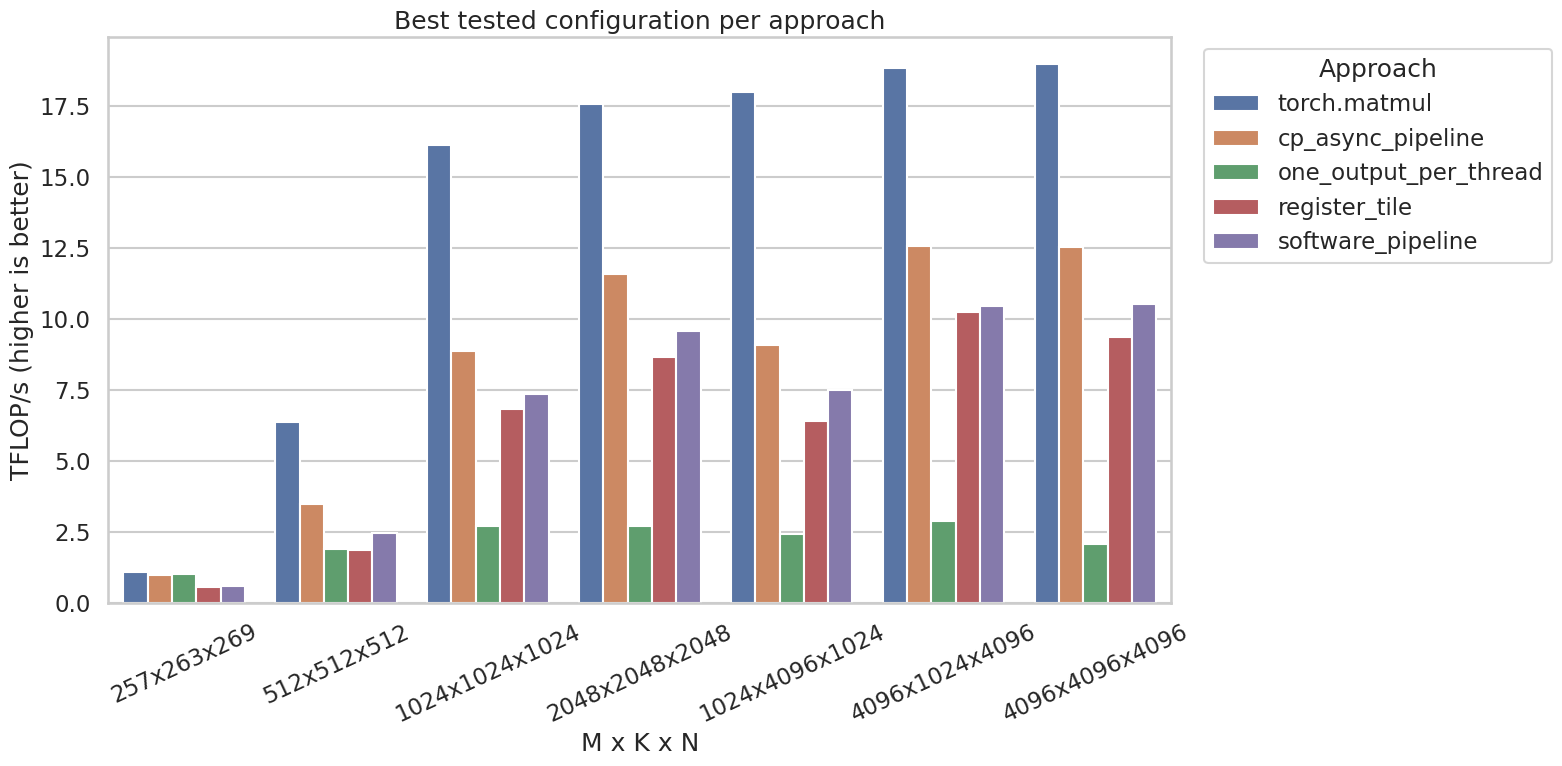

In [6]:
custom_results = results[results["approach"] != "torch.matmul"]
best_indices = custom_results.groupby(["shape", "approach"])["tflops"].idxmax()
best_custom = custom_results.loc[best_indices]
torch_results = results[results["approach"] == "torch.matmul"]
best_results = pd.concat([torch_results, best_custom], ignore_index=True)

sns.set_theme(style="whitegrid", context="talk")
figure, axis = plt.subplots(figsize=(16, 8))
sns.barplot(data=best_results, x="shape", y="tflops", hue="approach", ax=axis)
axis.set_title("Best tested configuration per approach")
axis.set_xlabel("M x K x N")
axis.set_ylabel("TFLOP/s (higher is better)")
axis.tick_params(axis="x", rotation=25)
axis.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "best_approach_by_shape.png", dpi=160)
plt.show()

## Plot 2: tile sensitivity

Every point is one `(approach, config, shape)` measurement. This makes it
obvious whether an optimization is genuinely robust or only wins for one
carefully chosen tile.

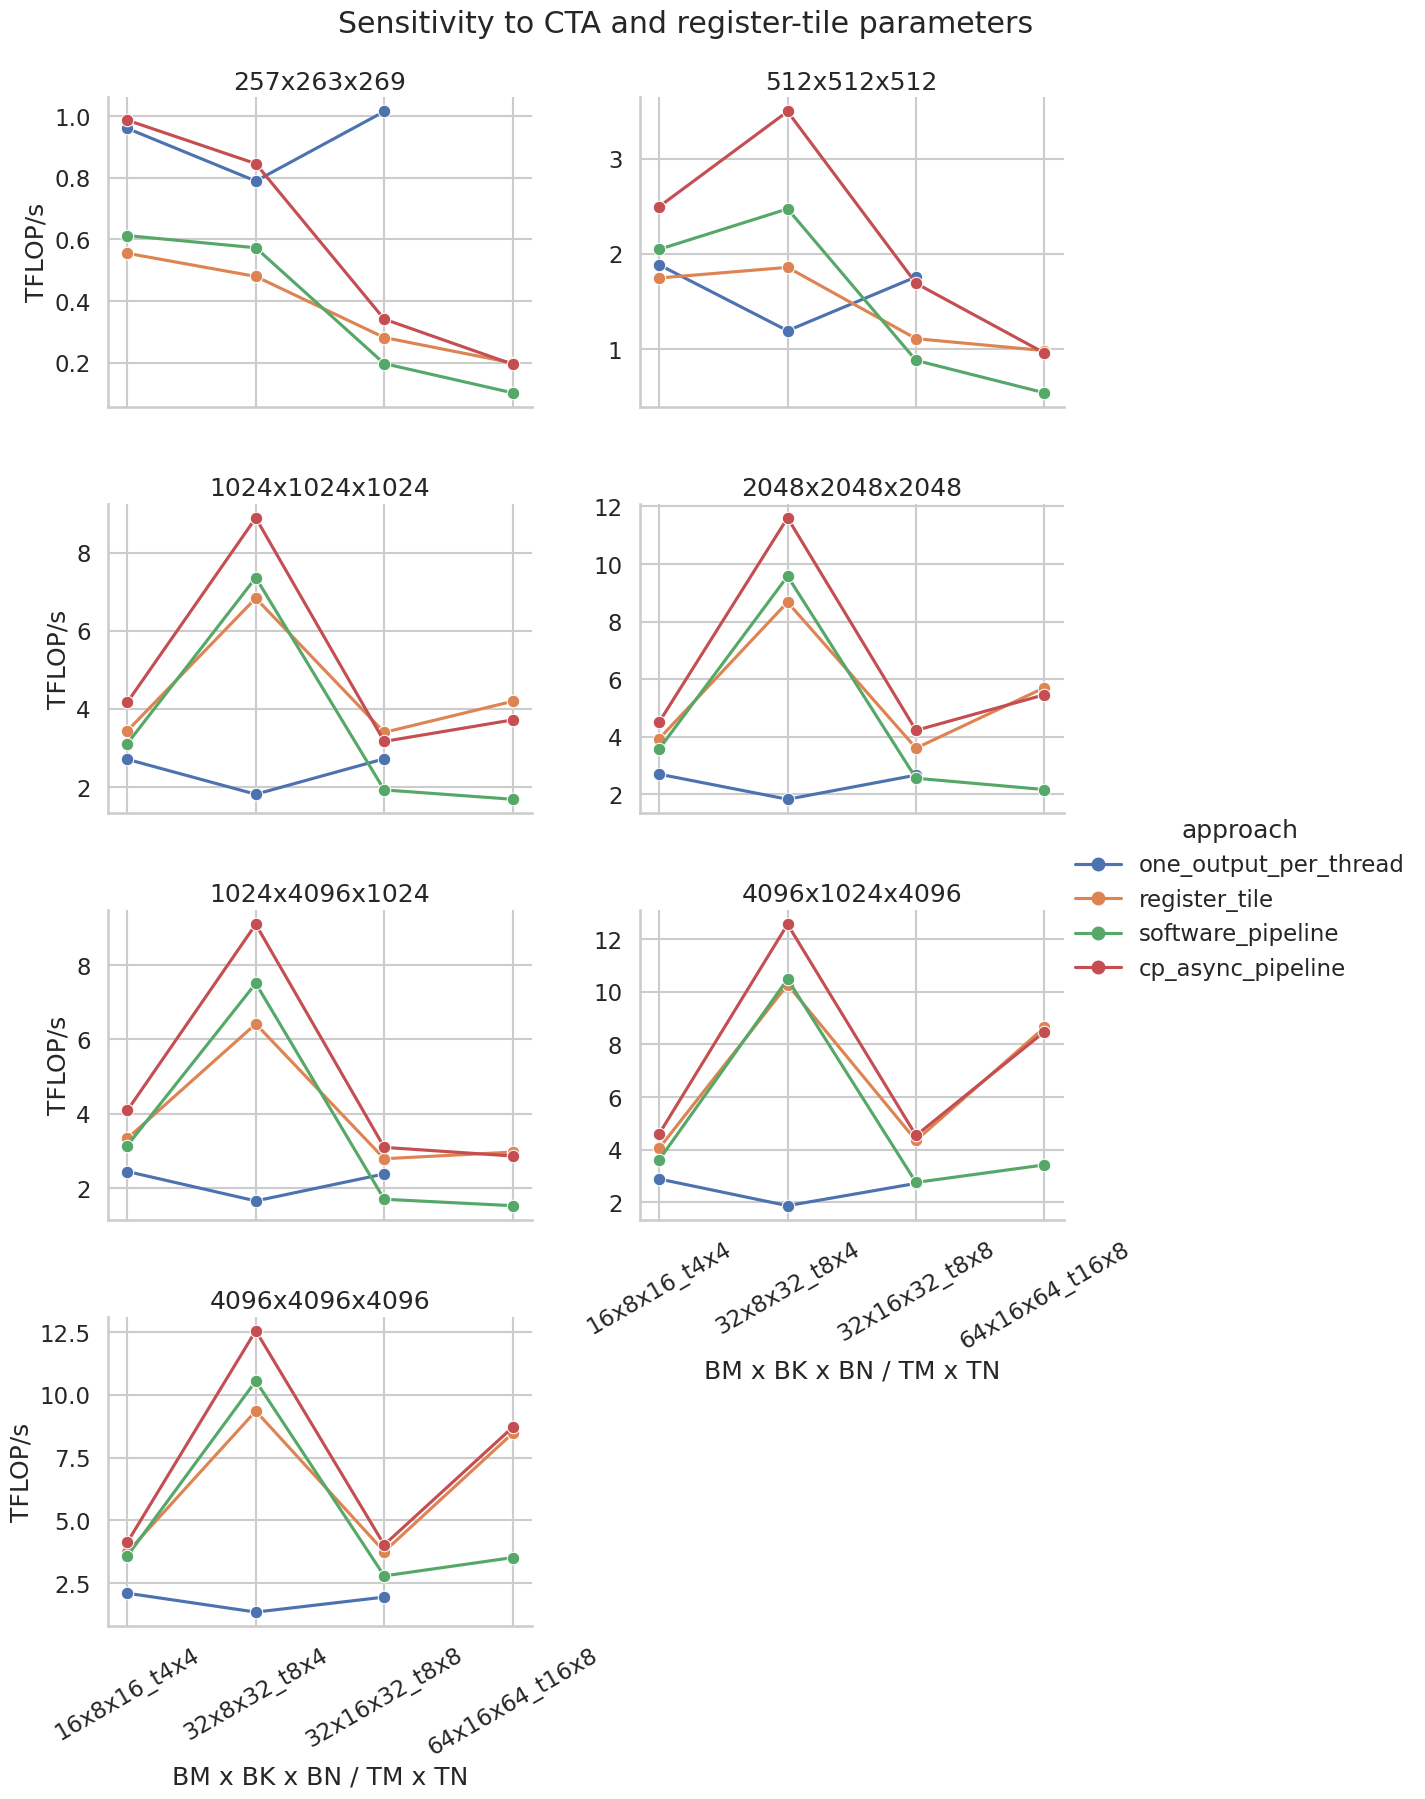

In [7]:
tile_plot = sns.relplot(
    data=custom_results,
    x="config",
    y="tflops",
    hue="approach",
    col="shape",
    col_wrap=2,
    kind="line",
    marker="o",
    height=4.2,
    aspect=1.35,
    facet_kws={"sharey": False},
)
tile_plot.set_axis_labels("BM x BK x BN / TM x TN", "TFLOP/s")
tile_plot.set_titles("{col_name}")
for axis in tile_plot.axes.flat:
    axis.tick_params(axis="x", rotation=30)
tile_plot.figure.suptitle("Sensitivity to CTA and register-tile parameters", y=1.02)
tile_plot.figure.savefig(
    OUTPUT_DIR / "tile_sensitivity.png", dpi=160, bbox_inches="tight"
)
plt.show()

## Plot 3: median performance across shapes

The heatmap summarizes tuning stability. A single spectacular result cannot
hide a configuration that performs poorly on the other matrix shapes.

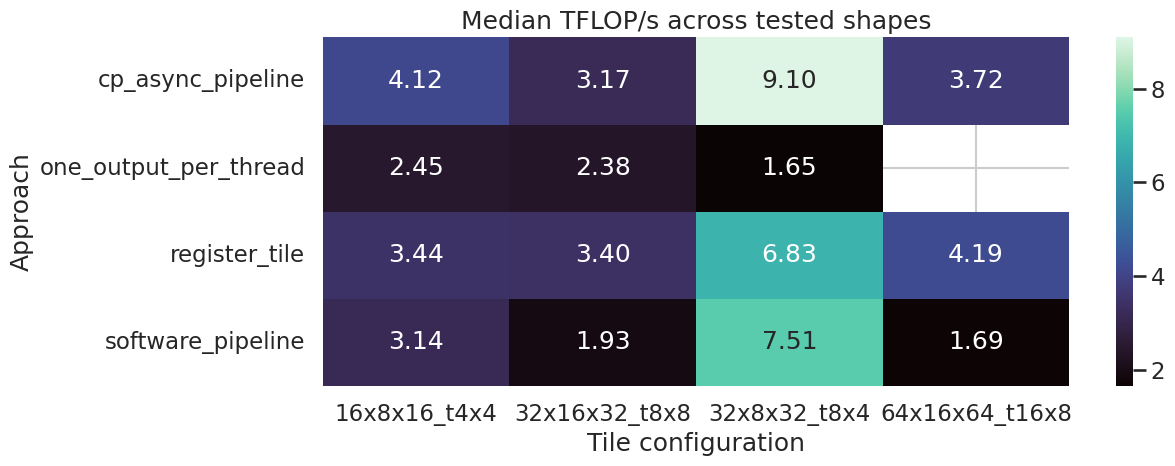

In [8]:
heatmap_data = custom_results.pivot_table(
    index="approach", columns="config", values="tflops", aggfunc="median"
)
figure, axis = plt.subplots(figsize=(13, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="mako", ax=axis)
axis.set_title("Median TFLOP/s across tested shapes")
axis.set_xlabel("Tile configuration")
axis.set_ylabel("Approach")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "median_tflops_heatmap.png", dpi=160)
plt.show()

## Winners and reproducibility metadata

In [9]:
winners = best_results.sort_values(["shape", "tflops"], ascending=[True, False])[
    ["shape", "approach", "config", "median_ms", "tflops", "speedup_vs_torch"]
]
display(winners)

metadata = {
    "gpu": torch.cuda.get_device_name(DEVICE),
    "compute_capability": CAPABILITY,
    "torch": torch.__version__,
    "torch_cuda": torch.version.cuda,
    "strict_fp32": torch.get_float32_matmul_precision(),
    "quick": QUICK,
    "shapes": SHAPES,
    "configs": [asdict(config) for config in CONFIGS],
    "extension": EXTENSION_NAME,
}
(OUTPUT_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print(json.dumps(metadata, indent=2))
print(f"Artifacts written to {OUTPUT_DIR.resolve()}")

,shape,approach,config,median_ms,tflops,speedup_vs_torch
2,1024x1024x1024,torch.matmul,cuBLAS strict FP32,0.133120,16.131938,1.000000
7,1024x1024x1024,cp_async_pipeline,32x8x32_t8x4,0.241664,8.886237,0.550847
10,1024x1024x1024,software_pipeline,32x8x32_t8x4,0.291840,7.358428,0.456140
9,1024x1024x1024,register_tile,32x8x32_t8x4,0.314368,6.831114,0.423453
8,1024x1024x1024,one_output_per_thread,32x16x32_t8x8,0.788480,2.723574,0.168831
4,1024x4096x1024,torch.matmul,cuBLAS strict FP32,0.477184,18.001305,1.000000
11,1024x4096x1024,cp_async_pipeline,32x8x32_t8x4,0.944128,9.098274,0.505423
14,1024x4096x1024,software_pipeline,32x8x32_t8x4,1.143808,7.509944,0.417189
13,1024x4096x1024,register_tile,32x8x32_t8x4,1.338368,6.418215,0.356542
12,1024x4096x1024,one_output_per_thread,16x8x16_t4x4,3.512320,2.445658,0.135860


{
  "gpu": "NVIDIA A100-SXM4-40GB",
  "compute_capability": [
    8,
    0
  ],
  "torch": "2.11.0+cu130",
  "torch_cuda": "13.0",
  "strict_fp32": "highest",
  "quick": false,
  "shapes": [
    [
      257,
      263,
      269
    ],
    [
      512,
      512,
      512
    ],
    [
      1024,
      1024,
      1024
    ],
    [
      2048,
      2048,
      2048
    ],
    [
      1024,
      4096,
      1024
    ],
    [
      4096,
      1024,
      4096
    ],
    [
      4096,
      4096,
      4096
    ]
  ],
  "configs": [
    {
      "name": "16x8x16_t4x4",
      "BM": 16,
      "BK": 8,
      "BN": 16,
      "TM": 4,
      "TN": 4
    },
    {
      "name": "32x8x32_t8x4",
      "BM": 32,
      "BK": 8,
      "BN": 32,
      "TM": 8,
      "TN": 4
    },
    {
      "name": "32x16x32_t8x8",
      "BM": 32,
      "BK": 16,
      "BN": 32,
      "TM": 8,
      "TN": 8
    },
    {
      "name": "64x16x64_t16x8",
      "BM": 64,
      "BK": 16,
      "BN": 64,
      "TM": 16,